# Merge all closed-reference feature tables (cleaned, no filter)

Calculate per-study closed-reference keeping rate, plot the study-level retention distribution, then merge all closed-reference BIOM tables without filtering.

In [1]:
from pathlib import Path
import biom
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

metadata_path = "/home/hexincheng/projects/hxc/oral_project/dada2_filter/metadata-v2-merge-cleaned.csv"
output_dir = Path("/beegfs/dongbiao/oral")
threshold = 0.80

plt.rcParams.update({
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

metadata = pd.read_csv(metadata_path)
metadata.head()

<ipython-input-1-63bfc86372f5>:21: DtypeWarning: Columns (3,5) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata = pd.read_csv(metadata_path)


,bioproject,sample_id,subject_id,age,age_info,bmi,sex,platform,sequencing_region,pcr_primers,...,bmi_cleaned_group,sex_cleaned,platform_cleaned,sequencing_region_cleaned,country_cleaned,continent_group,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned
0,CNP0002325,B1,B1,NaN,6-14,NaN,NaN,Illumina MiSeq,V3-V4,NaN,...,NaN,NaN,Illumina MiSeq,V3-V4,China,Asia,tooth,Oral,Yes,Dental Caries
1,CNP0002325,B3,B3,NaN,6-14,NaN,NaN,Illumina MiSeq,V3-V4,NaN,...,NaN,NaN,Illumina MiSeq,V3-V4,China,Asia,tooth,Oral,Yes,Dental Caries
2,CNP0002325,B4,B4,NaN,6-14,NaN,NaN,Illumina MiSeq,V3-V4,NaN,...,NaN,NaN,Illumina MiSeq,V3-V4,China,Asia,tooth,Oral,Yes,Dental Caries
3,CNP0002325,B5,B5,NaN,6-14,NaN,NaN,Illumina MiSeq,V3-V4,NaN,...,NaN,NaN,Illumina MiSeq,V3-V4,China,Asia,tooth,Oral,Yes,Dental Caries
4,CNP0002325,B6,B6,NaN,6-14,NaN,NaN,Illumina MiSeq,V3-V4,NaN,...,NaN,NaN,Illumina MiSeq,V3-V4,China,Asia,tooth,Oral,Yes,Dental Caries


In [2]:
ratio = []
study_id = []
total_before = []
total_after = []

for name in metadata.bioproject.unique():
    table = biom.load_table(f"/beegfs/dongbiao/oral/{name}/results/DADA2.biom")
    inter_sid = np.intersect1d(metadata.sample_id.values, table.ids(axis="sample"))
    table.filter(inter_sid, axis="sample")
    table.remove_empty()
    totall_1 = np.sum(table.sum(axis="sample"))

    table = biom.load_table(f"/beegfs/dongbiao/oral/{name}/results/extracted-feature-table/feature-table.biom")
    inter_sid = np.intersect1d(metadata.sample_id.values, table.ids(axis="sample"))
    table.filter(inter_sid, axis="sample")
    table.remove_empty()
    totall_2 = np.sum(table.sum(axis="sample"))

    study_id.append(name)
    total_before.append(totall_1)
    total_after.append(totall_2)
    ratio.append(totall_2 / totall_1)

all_res = pd.DataFrame({
    "study_id": study_id,
    "total_before": total_before,
    "total_after": total_after,
    "ratio": ratio,
})

all_res.to_csv(output_dir / "study_close_reference_keeping_rate_cleaned_all.csv", index=False)
all_study = all_res.study_id.values

all_res.head()

,study_id,total_before,total_after,ratio
0,CNP0002325,6492480.0,4862564.0,0.748953
1,OEP000837,8641151.0,7084771.0,0.819887
2,PRJCA005537,50936795.0,46831672.0,0.919408
3,PRJCA006963,10489614.0,9848360.0,0.938868
4,PRJDB10426,15013034.0,11706682.0,0.779768


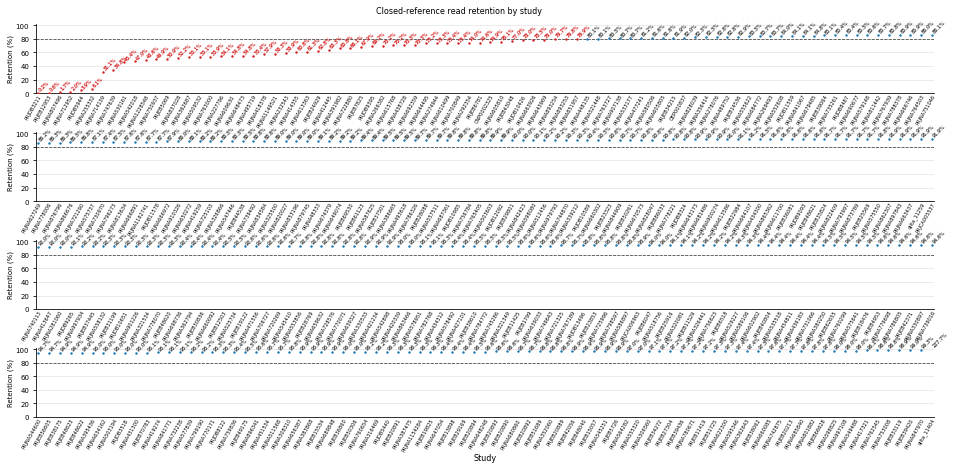

PosixPath('/beegfs/dongbiao/oral/study_close_reference_keeping_rate_cleaned_all.png')

In [3]:
plot_df = all_res.sort_values(["ratio", "study_id"]).reset_index(drop=True)
plot_df["retention_pct"] = plot_df["ratio"] * 100
plot_df["flag"] = plot_df["ratio"] < threshold
n_panels = min(4, len(plot_df))
chunks = [chunk for chunk in np.array_split(np.arange(len(plot_df)), n_panels) if len(chunk) > 0]

fig, axes = plt.subplots(
    len(chunks),
    1,
    figsize=(13.333, max(7.0, 1.6 * len(chunks) + 0.3)),
    squeeze=False,
    sharey=True,
)
fig.suptitle("Closed-reference read retention by study", fontsize=8, y=0.955)

for panel_index, chunk in enumerate(chunks, start=1):
    ax = axes[panel_index - 1, 0]
    panel = plot_df.iloc[chunk].copy()
    positions = np.arange(len(panel))
    panel_max = max(float(panel["retention_pct"].max()), threshold * 100)
    upper_limit = min(102.0, panel_max + 4.0)

    for pos, (_, row) in enumerate(panel.iterrows()):
        flagged = bool(row["flag"])
        color = "#d62728" if flagged else "#1f77b4"
        ax.scatter(pos, row["retention_pct"], s=2, color=color, zorder=3)
        ax.text(
            pos,
            min(upper_limit + 0.6, row["retention_pct"] + 1.4),
            f"{row['retention_pct']:.1f}%",
            rotation=45,
            ha="left",
            va="bottom",
            size=4.5,
            fontweight="bold",
            color="#d62728" if flagged else "#4d4d4d",
        )

    ax.axhline(threshold * 100, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.set_xticks(positions)
    ax.set_xticklabels(panel["study_id"], rotation=60, ha="right", rotation_mode="anchor", fontsize=5)
    ax.tick_params(axis="x", pad=0.1, length=0)
    ax.set_ylabel("Retention (%)", fontsize=7, labelpad=2)
    ax.set_yticks(np.arange(0, 101, 20))
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
    ax.margins(x=0.002)
    ax.set_ylim(0, 102)

axes[-1, 0].set_xlabel("Study", fontsize=8, labelpad=1)
fig.subplots_adjust(left=0.06, right=0.995, top=0.92, bottom=0.14, hspace=0.56)
plot_path = output_dir / "study_close_reference_keeping_rate_cleaned_all.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plot_path

In [4]:
n = 1
num_sid_table = []
num_sid_df = []

for name in all_study:
    if n == 1:
        table = biom.load_table(f"/beegfs/dongbiao/oral/{name}/results/extracted-feature-table/feature-table.biom")
        inter_sid = np.intersect1d(metadata.sample_id.values, table.ids(axis="sample"))
        table.filter(inter_sid, axis="sample")
        table.remove_empty()
        num_sid_table.append(table.shape[1])
        num_sid_df.append(metadata.loc[metadata.bioproject.values == name].shape[0])
    else:
        temp = biom.load_table(f"/beegfs/dongbiao/oral/{name}/results/extracted-feature-table/feature-table.biom")
        inter_sid = np.intersect1d(metadata.sample_id.values, temp.ids(axis="sample"))
        temp.filter(inter_sid, axis="sample")
        temp.remove_empty()

        table = table.merge(temp)
        num_sid_table.append(temp.shape[1])
        num_sid_df.append(metadata.loc[metadata.bioproject.values == name].shape[0])
    n = n + 1

table.remove_empty()
table

62782 x 115345 <class 'biom.table.Table'> with 10598176 nonzero entries (0% dense)

In [5]:
merge_summary = pd.DataFrame({
    "study_id": all_study,
    "sample_count_in_closed_reference_table": num_sid_table,
    "sample_count_in_metadata": num_sid_df,
})

output_name = f"table_gg2_id99_cleaned_{table.shape[0]}_{table.shape[1]}_all.biom"
output_path = output_dir / output_name
summary_path = output_dir / "merge_closed_reference_tables_cleaned_all_summary.csv"

with biom.util.biom_open(str(output_path), "w") as handle:
    table.to_hdf5(handle, generated_by="merge_closed_reference_tables_cleaned_all.ipynb")

merge_summary.to_csv(summary_path, index=False)

print("merged table shape:", table.shape)
print("saved biom:", output_path)
print("saved summary:", summary_path)
merge_summary.head()

merged table shape: (62782, 115345)
saved biom: /beegfs/dongbiao/oral/table_gg2_id99_cleaned_62782_115345_all.biom
saved summary: /beegfs/dongbiao/oral/merge_closed_reference_tables_cleaned_all_summary.csv


,study_id,sample_count_in_closed_reference_table,sample_count_in_metadata
0,CNP0002325,78,78
1,OEP000837,86,86
2,PRJCA005537,192,192
3,PRJCA006963,103,103
4,PRJDB10426,156,156


## Filtering the characteristics of mitochondria and chloroplasts

Based on the taxonomy table, the features (OTUs) with `Class` as `c__Chloroplast` and `Family` as `f__Mitochondria` were excluded, resulting in a filtered biom table.

In [6]:
table = biom.load_table(str(output_path))
fid = table.ids(axis="observation")
table

62782 x 115345 <class 'biom.table.Table'> with 10598176 nonzero entries (0% dense)

In [7]:
tax = pd.read_csv("/beegfs/dongbiao/greengene2/exported-taxonomy/taxonomy.tsv", sep="\t", low_memory=False, index_col=0)
tax = tax.loc[fid]
tax = tax.loc[:, "Taxon"].str.split(';', expand=True)
tax = tax.iloc[:, 0: 7]
tax.columns = ['Kingdom', 'Phylum', 'Class', 'Order', 'Family', 'Genus', 'Species']

In [8]:
fid_remove_tax_1 = tax.loc[tax.Class.values == " c__Chloroplast"].index.values
fid_remove_tax_2 = tax.loc[tax.Family.values == " f__Mitochondria"].index.values
fid_remove_tax = list(fid_remove_tax_1) + list(fid_remove_tax_2)

In [9]:
keep_fid = [i for i in fid if i not in fid_remove_tax]

table_remove_tax = table.filter(keep_fid, axis='observation', inplace=False)
table_remove_tax.remove_empty()

61235 x 115338 <class 'biom.table.Table'> with 10539612 nonzero entries (0% dense)

In [10]:
with biom.util.biom_open(str(output_dir / f"table_gg2_id99_{table_remove_tax.shape[0]}_{table_remove_tax.shape[1]}_v2.biom"), 'w') as f:
    table_remove_tax.to_hdf5(f, 'example')